# Inspector de tornillos: OK / DEFECTO

## Paso 1: cargar las fotos y mirarlas
Antes de entrenar nada hay que saber qué datos tenemos. Contamos las fotos de cada clase y mostramos algunas.

In [1]:
from pathlib import Path

DATOS = Path("datos")
CLASES = ["ok", "defecto"]

for clase in CLASES:
    fotos = sorted((DATOS / clase).glob("*.jpeg"))
    print(f"{clase}: {len(fotos)} fotos")

ok: 29 fotos
defecto: 32 fotos


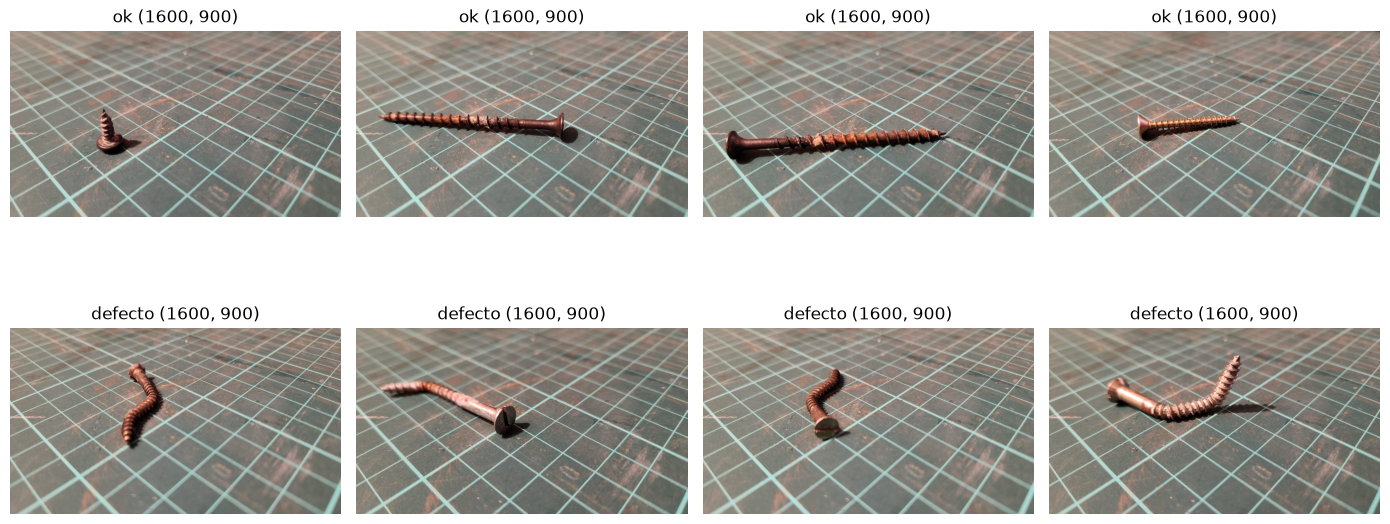

In [2]:
import matplotlib.pyplot as plt
from PIL import Image

fig, ejes = plt.subplots(2, 4, figsize=(14, 7))
for fila, clase in enumerate(CLASES):
    fotos = sorted((DATOS / clase).glob("*.jpeg"))[:4]
    for col, ruta in enumerate(fotos):
        img = Image.open(ruta)
        ejes[fila, col].imshow(img)
        ejes[fila, col].set_title(f"{clase} {img.size}")
        ejes[fila, col].axis("off")
plt.tight_layout()
plt.show()

## Paso 2: preparar los datos
El modelo necesita números, no archivos. Convertimos cada foto en una tabla de píxeles de 224x224x3 (alto, ancho, color RGB) y guardamos su etiqueta: 0 = ok, 1 = defecto.

In [3]:
import numpy as np

TAM = (224, 224)
X, y = [], []

for etiqueta, clase in enumerate(CLASES):
    for ruta in sorted((DATOS / clase).glob("*.jpeg")):
        img = Image.open(ruta).convert("RGB").resize(TAM)
        X.append(np.array(img))
        y.append(etiqueta)

X = np.array(X, dtype="float32")
y = np.array(y)
print("X:", X.shape, "| y:", y.shape)
print("ok (0) y defecto (1):", np.bincount(y))

X: (61, 224, 224, 3) | y: (61,)
ok (0) y defecto (1): [29 32]


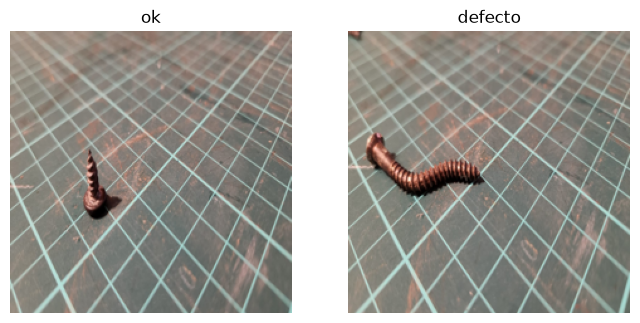

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(8, 4))
for ax, i in zip(ejes, [0, len(y) - 1]):
    ax.imshow(X[i].astype("uint8"))
    ax.set_title(CLASES[y[i]])
    ax.axis("off")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X_ent, X_val, y_ent, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("entrenamiento:", len(X_ent), np.bincount(y_ent))
print("validacion:   ", len(X_val), np.bincount(y_val))

entrenamiento: 48 [23 25]
validacion:    13 [6 7]


In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Parte 1: la base que ya sabe ver (MobileNetV2), congelada
base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet"
)
base.trainable = False

# Parte 2: la cabeza nueva, la única que se entrena con mis fotos
entrada = layers.Input(shape=(224, 224, 3))
x = layers.Rescaling(1 / 127.5, offset=-1)(entrada)   # pasa de 0-255 a -1...1
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)                # resume lo que vio
x = layers.Dropout(0.3)(x)                            # apaga conexiones al azar
salida = layers.Dense(1, activation="sigmoid")(x)     # número entre 0 y 1

modelo = models.Model(entrada, salida)

print("Parámetros de la base (congelados):", base.count_params())
print("Parámetros que se van a entrenar:  ", sum(w.shape.num_elements() for w in modelo.trainable_weights))


Parámetros de la base (congelados): 2257984
Parámetros que se van a entrenar:   1281


In [7]:
tf.keras.utils.set_random_seed(42)   # misma semilla: resultados repetibles

modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

historia = modelo.fit(
    X_ent, y_ent,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=8,
)


Epoch 1/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 320ms/step - accuracy: 0.4167 - loss: 0.9059 - val_accuracy: 0.6154 - val_loss: 0.6748
Epoch 2/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step - accuracy: 0.5625 - loss: 0.7454 - val_accuracy: 0.7692 - val_loss: 0.6060
Epoch 3/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - accuracy: 0.6458 - loss: 0.6595 - val_accuracy: 0.7692 - val_loss: 0.5755
Epoch 4/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - accuracy: 0.7083 - loss: 0.5910 - val_accuracy: 0.8462 - val_loss: 0.5440
Epoch 5/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 140ms/step - accuracy: 0.6458 - loss: 0.6089 - val_accuracy: 0.8462 - val_loss: 0.4909
Epoch 6/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 150ms/step - accuracy: 0.6875 - loss: 0.5710 - val_accuracy: 0.9231 - val_loss: 0.4572
Epoch 7/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 143ms/step - accuracy: 0.7500 - loss: 0.4690 - val_accuracy: 0.8462 - val_loss: 0.4316
Epoch 8/15
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step - accuracy: 0.7500 - loss: 0.4623 - val_accuracy: 0.9231 - val_loss:

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 883ms/step
               dijo OK   dijo DEFECTO
era OK             5           1
era DEFECTO        0           7

Falló 1 de 13 fotos


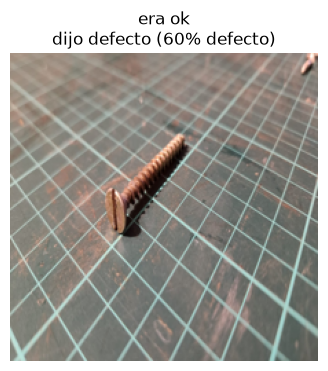

In [8]:
from sklearn.metrics import confusion_matrix

# El modelo da un número entre 0 y 1; si pasa de 0,5 decimos DEFECTO
prob = modelo.predict(X_val).ravel()
pred = (prob > 0.5).astype(int)

# La tablita de 2 por 2
tabla = confusion_matrix(y_val, pred)
print("               dijo OK   dijo DEFECTO")
print(f"era OK         {tabla[0,0]:5d}     {tabla[0,1]:7d}")
print(f"era DEFECTO    {tabla[1,0]:5d}     {tabla[1,1]:7d}")

# Las fotos que falló
fallas = np.where(pred != y_val)[0]
print(f"\nFalló {len(fallas)} de {len(y_val)} fotos")

if len(fallas) > 0:
    fig, ejes = plt.subplots(1, len(fallas), figsize=(4 * len(fallas), 4), squeeze=False)
    for ax, i in zip(ejes[0], fallas):
        ax.imshow(X_val[i].astype("uint8"))
        ax.set_title(f"era {CLASES[y_val[i]]}\ndijo {CLASES[pred[i]]} ({prob[i]:.0%} defecto)")
        ax.axis("off")
    plt.show()


prueba_final: OK = 12 | DEFECTO = 9
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1000ms/step
               dijo OK   dijo DEFECTO
era OK             9           3
era DEFECTO        0           9

Aciertos: 18 de 21


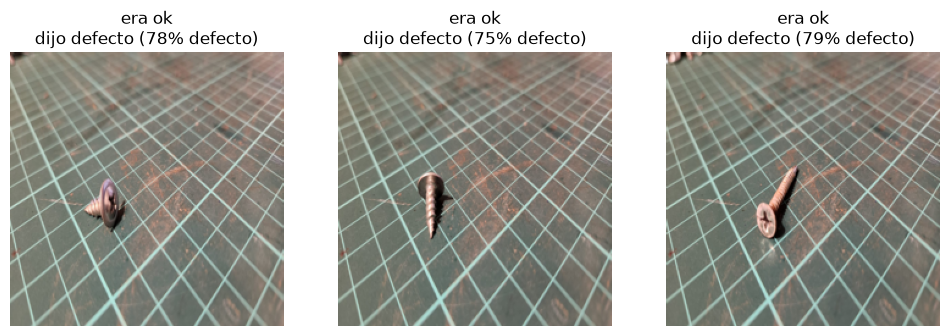

In [9]:
# Cargar las fotos del examen final y prepararlas igual que las de entrenamiento
X_fin, y_fin = [], []
for etiqueta, clase in enumerate(CLASES):
    for ruta in sorted((DATOS / "prueba_final" / clase).glob("*.jpeg")):
        img = Image.open(ruta).convert("RGB").resize(TAM)        
        X_fin.append(np.array(img))
        y_fin.append(etiqueta)
X_fin = np.array(X_fin, dtype="float32")
y_fin = np.array(y_fin)
print("prueba_final: OK =", (y_fin == 0).sum(), "| DEFECTO =", (y_fin == 1).sum())

# Preguntarle al modelo y armar la tablita
prob_fin = modelo.predict(X_fin).ravel()
pred_fin = (prob_fin > 0.5).astype(int)
tabla = confusion_matrix(y_fin, pred_fin)
print("               dijo OK   dijo DEFECTO")
print(f"era OK         {tabla[0,0]:5d}     {tabla[0,1]:7d}")
print(f"era DEFECTO    {tabla[1,0]:5d}     {tabla[1,1]:7d}")
print(f"\nAciertos: {(pred_fin == y_fin).sum()} de {len(y_fin)}")

# Mostrar las fotos que falló
fallas = np.where(pred_fin != y_fin)[0]
if len(fallas) > 0:
    cols = min(len(fallas), 4)
    filas = int(np.ceil(len(fallas) / cols))
    fig, ejes = plt.subplots(filas, cols, figsize=(4 * cols, 4 * filas), squeeze=False)
    for ax in ejes.ravel():
        ax.axis("off")
    for ax, i in zip(ejes.ravel(), fallas):
        ax.imshow(X_fin[i].astype("uint8"))
        ax.set_title(f"era {CLASES[y_fin[i]]}\ndijo {CLASES[pred_fin[i]]} ({prob_fin[i]:.0%} defecto)")
    plt.show()


In [10]:
def correr(semilla):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(semilla)   # ahora ANTES de armar el modelo

    base = tf.keras.applications.MobileNetV2(
        input_shape=(224, 224, 3), include_top=False, weights="imagenet"
    )
    base.trainable = False

    entrada = layers.Input(shape=(224, 224, 3))
    x = layers.Rescaling(1 / 127.5, offset=-1)(entrada)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(1, activation="sigmoid")(x)
    m = models.Model(entrada, salida)

    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    m.fit(X_ent, y_ent, validation_data=(X_val, y_val),
          epochs=15, batch_size=8, verbose=0)

    pred_val = (m.predict(X_val, verbose=0).ravel() > 0.5).astype(int)
    pred_fin = (m.predict(X_fin, verbose=0).ravel() > 0.5).astype(int)
    return {
        "val": (pred_val == y_val).sum(),
        "fin": (pred_fin == y_fin).sum(),
        "ok_fin": ((pred_fin == 0) & (y_fin == 0)).sum(),
        "def_fin": ((pred_fin == 1) & (y_fin == 1)).sum(),
    }

resultados = []
for semilla in [1, 2, 3, 4, 5]:
    r = correr(semilla)
    resultados.append(r)
    print(f"semilla {semilla}: validación {r['val']}/13 | prueba_final {r['fin']}/21 "
          f"(OK {r['ok_fin']}/12, DEFECTO {r['def_fin']}/9)")

finales = [r["fin"] for r in resultados]
print(f"\nprueba_final: mínimo {min(finales)}/21, máximo {max(finales)}/21, "
      f"promedio {sum(finales)/len(finales):.1f}/21")



semilla 1: validación 11/13 | prueba_final 16/21 (OK 7/12, DEFECTO 9/9)
semilla 2: validación 11/13 | prueba_final 16/21 (OK 7/12, DEFECTO 9/9)
semilla 3: validación 10/13 | prueba_final 15/21 (OK 6/12, DEFECTO 9/9)
semilla 4: validación 12/13 | prueba_final 16/21 (OK 7/12, DEFECTO 9/9)
semilla 5: validación 10/13 | prueba_final 16/21 (OK 7/12, DEFECTO 9/9)

prueba_final: mínimo 15/21, máximo 16/21, promedio 15.8/21


In [11]:
def correr_aumento(semilla):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(semilla)

    base = tf.keras.applications.MobileNetV2(
        input_shape=(224, 224, 3), include_top=False, weights="imagenet"
    )
    base.trainable = False

    entrada = layers.Input(shape=(224, 224, 3))
    # Aumento de datos: solo actúa al entrenar, y con cambios suaves
    x = layers.RandomFlip("horizontal")(entrada)       # espejo izquierda-derecha
    x = layers.RandomRotation(0.02)(x)                 # giro de unos 7 grados
    x = layers.RandomBrightness(0.15)(x)               # un poco más o menos de brillo
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(1, activation="sigmoid")(x)
    m = models.Model(entrada, salida)

    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    m.fit(X_ent, y_ent, validation_data=(X_val, y_val),
          epochs=15, batch_size=8, verbose=0)

    pred_val = (m.predict(X_val, verbose=0).ravel() > 0.5).astype(int)
    pred_fin = (m.predict(X_fin, verbose=0).ravel() > 0.5).astype(int)
    return {
        "val": (pred_val == y_val).sum(),
        "fin": (pred_fin == y_fin).sum(),
        "ok_fin": ((pred_fin == 0) & (y_fin == 0)).sum(),
        "def_fin": ((pred_fin == 1) & (y_fin == 1)).sum(),
    }

resultados_aug = []
for semilla in [1, 2, 3, 4, 5]:
    r = correr_aumento(semilla)
    resultados_aug.append(r)
    print(f"semilla {semilla}: validación {r['val']}/13 | prueba_final {r['fin']}/21 "
          f"(OK {r['ok_fin']}/12, DEFECTO {r['def_fin']}/9)")

finales_aug = [r["fin"] for r in resultados_aug]
print(f"\nCON aumento: mínimo {min(finales_aug)}/21, máximo {max(finales_aug)}/21, "
      f"promedio {sum(finales_aug)/len(finales_aug):.1f}/21")
print(f"SIN aumento: mínimo {min(finales)}/21, máximo {max(finales)}/21, "
      f"promedio {sum(finales)/len(finales):.1f}/21")


semilla 1: validación 10/13 | prueba_final 15/21 (OK 6/12, DEFECTO 9/9)
semilla 2: validación 10/13 | prueba_final 15/21 (OK 6/12, DEFECTO 9/9)
semilla 3: validación 11/13 | prueba_final 15/21 (OK 6/12, DEFECTO 9/9)
semilla 4: validación 11/13 | prueba_final 14/21 (OK 5/12, DEFECTO 9/9)
semilla 5: validación 11/13 | prueba_final 16/21 (OK 7/12, DEFECTO 9/9)

CON aumento: mínimo 14/21, máximo 16/21, promedio 15.0/21
SIN aumento: mínimo 15/21, máximo 16/21, promedio 15.8/21


In [12]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(1)

base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet"
)
base.trainable = False

entrada = layers.Input(shape=(224, 224, 3))
x = layers.Rescaling(1 / 127.5, offset=-1)(entrada)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
salida = layers.Dense(1, activation="sigmoid")(x)
modelo_final = models.Model(entrada, salida)

modelo_final.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
modelo_final.fit(X_ent, y_ent, validation_data=(X_val, y_val),
                 epochs=15, batch_size=8, verbose=0)

# Comprobar que rinde lo esperado antes de guardarlo
pred_fin = (modelo_final.predict(X_fin, verbose=0).ravel() > 0.5).astype(int)
print("prueba_final:", (pred_fin == y_fin).sum(), "de", len(y_fin))
print("  OK bien:      ", ((pred_fin == 0) & (y_fin == 0)).sum(), "de 12")
print("  DEFECTO bien: ", ((pred_fin == 1) & (y_fin == 1)).sum(), "de 9")

# Guardar el modelo en un archivo
modelo_final.save("modelo_inspector.keras")
print("\nModelo guardado en: modelo_inspector.keras")



prueba_final: 16 de 21
  OK bien:       7 de 12
  DEFECTO bien:  9 de 9

Modelo guardado en: modelo_inspector.keras
